# A calibrated Gaussian rate model: paths, fit, and sampling uncertainty

**Question.** What distributions does the configured one-factor rate generator
produce, and which differences are calibration error, sampling error, or
time-grid bias?

Use the illustrative 24 February 2026 SOFR curve and Black caplet surface,
positive mean reversion $\alpha=0.05$, 2,048 paths, and monthly dates for five
years. Parameters are calibrated to ATM caplet prices, not copied from Black
volatility quotes. These are model-implied pricing scenarios, **not forecasts**.
The returned values are decimal short rates, not discount factors or exposures.
[Setup](../README.md).

The implementation evolves a centered Gaussian factor by Euler steps:
$$x_{i+1}=(1-\alpha\Delta t_i)x_i+
\sigma(t_{i+1})\sqrt{\Delta t_i}\,Z_i,\qquad r_i=x_i+\phi_i.$$
Its deterministic shift uses the initial forward curve and a variance
recursion. These are not exact OU transitions; refining the output grid changes
the numerical evolution. Positive $\alpha$ is required by this low-level
Hull–White generator; a zero-alpha limit is not implemented here.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import quantsupport as qs
from market_data import load_market, read_configuration

market = load_market()
ref = market.quotes.reference_date
simulation_spec = read_configuration(
    "hullwhite",
    "simulation.json",
)
simulation_spec


{'market_index': 'SOFR',
 'model': {'HullWhite': {'alpha': 0.05,
   'parameter_source': {'Calibrated': {'source': {'Surface': {'market_index': 'SOFR'}},
     'calibration_basket': {'strike': 'Atm'}}}}},
 'n_paths': 2048,
 'seed': 42,
 'horizon': '5Y',
 'frequency': 'Monthly',
 'day_counter': 'Actual365'}

## Read the model specification as a set of financial choices

[simulation.json](data/simulation.json) contains the nested serialization
schema so it does not dominate the example. Its fields mean:

| Field | Meaning in this example |
| --- | --- |
| `market_index` | SOFR identifies the curve being simulated |
| `HullWhite.alpha` | Mean reversion, 0.05 per year |
| `parameter_source.Calibrated` | Fit a volatility schedule to the constructed market |
| `source.Surface` / `strike: Atm` | Use ATM caplet prices inferred from the SOFR Black surface |
| `horizon` / `frequency` | Five years of monthly output dates |
| `n_paths` / `seed` | 2,048 paths and a reproducible random-number sequence |
| `day_counter` | Actual/365 time coordinates |

The calibration translates Black caplet quotes into an absolute short-rate
volatility schedule. Substituting a quoted Black vol directly as `sigma` would
change the meaning of the model. You can change the path count or observation
frequency independently of the calibration source.

In [2]:
simulation_config = qs.SimulationConfiguration.from_dict(
    {
        **simulation_spec,
        "market_index": qs.MarketIndex.SOFR,
        "frequency": qs.Frequency.Monthly,
    }
)


def simulate(configuration):
    context = qs.PricingContext(
        quotes=market.quotes,
        curves=market.curves,
        csa_policy=market.csa_policy,
        volatility_surfaces=market.volatility_surfaces,
        simulations=[configuration],
    )

    with context:
        simulation = context.simulation(qs.MarketIndex.SOFR)
        print(
            simulation,
            "| average time step:",
            simulation.dt,
        )
        return simulation.paths(), simulation.dates(), simulation.calibration_diagnostics()


paths, dates, calibration = simulate(simulation_config)
print(
    "Rows are paths; columns are dates:",
    paths.shape,
)
paths.iloc[:5, :6]


Simulation(market_index='SOFR', n_paths=2048) | average time step: 0.08337899543378996
Rows are paths; columns are dates: (2048, 60)


,2026-03-24,2026-04-24,2026-05-24,2026-06-24,2026-07-24,2026-08-24
0,0.042755,0.038886,0.028061,0.030412,0.040298,0.038584
1,0.056412,0.056880,0.057723,0.048913,0.043499,0.045845
2,0.053049,0.047860,0.052986,0.051018,0.047342,0.045510
3,0.053642,0.060110,0.058658,0.062102,0.062104,0.058794
4,0.053250,0.058950,0.059167,0.055605,0.053898,0.049432


## Get one trajectory, one date, or the entire distribution

`paths()` copies the results into a DataFrame: a row is one trajectory and a
column is an ISO date. `dates()` returns the corresponding `qs.Date` values.
This simulation grid starts **after** the reference date; it contains no
time-zero column. `dt` is the average spacing in years. Calendar months have
different lengths, so use the actual dates for time integration.

Once copied out, these pandas values remain usable after the context closes.
`ctx.simulations()` lists all configured simulations; `ctx.simulation(index)`
selects one. Requesting an unconfigured index raises an error.

In [3]:
one_path = paths.iloc[0]  # All dates on the first trajectory.
terminal_rates = paths.iloc[:, -1]  # All trajectories at the last date.
summary = pd.DataFrame(
    {
        "mean": paths.mean(axis=0),
        "std_dev": paths.std(axis=0),
        "p05": paths.quantile(0.05),
        "median": paths.quantile(0.50),
        "p95": paths.quantile(0.95),
    }
)
summary.index = pd.to_datetime(summary.index)
summary.tail()


,mean,std_dev,p05,median,p95
2030-10-24,0.037427,0.022443,0.000413,0.037492,0.074022
2030-11-24,0.037404,0.022447,0.000721,0.037477,0.074333
2030-12-24,0.037389,0.022595,0.000538,0.037541,0.074736
2031-01-24,0.037397,0.022760,0.000114,0.037593,0.075277
2031-02-24,0.037379,0.022825,-0.000180,0.037459,0.076031


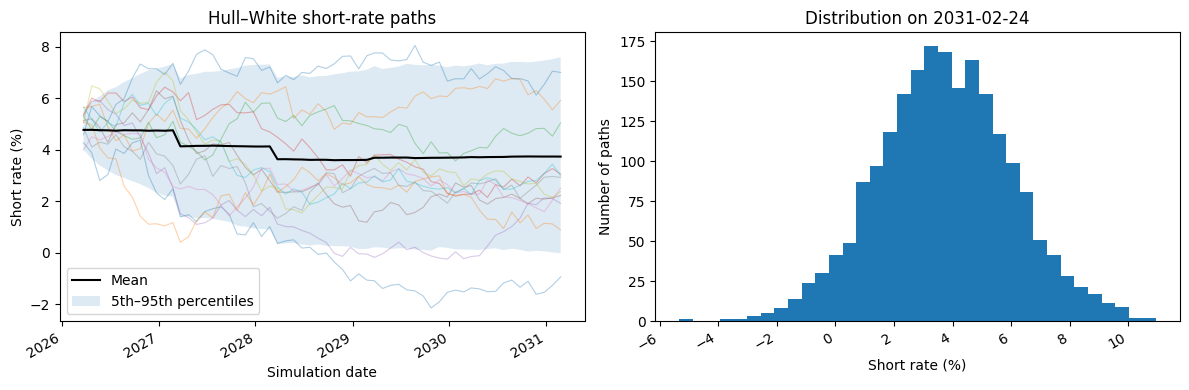

In [4]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4),
)
plot_dates = pd.to_datetime(paths.columns)
axes[0].plot(
    plot_dates,
    paths.iloc[:12].T * 100,
    alpha=0.35,
    linewidth=0.8,
)
axes[0].plot(
    summary.index,
    summary["mean"] * 100,
    color="black",
    label="Mean",
)
axes[0].fill_between(
    summary.index,
    summary["p05"] * 100,
    summary["p95"] * 100,
    alpha=0.15,
    label="5th–95th percentiles",
)
axes[0].set(
    title="Hull–White short-rate paths",
    xlabel="Simulation date",
    ylabel="Short rate (%)",
)
axes[0].legend()
axes[1].hist(
    terminal_rates * 100,
    bins=35,
)
axes[1].set(
    title=f"Distribution on {dates[-1]}",
    xlabel="Short rate (%)",
    ylabel="Number of paths",
)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


The shaded band is a cross-sectional range of simulated rates at each date,
not a confidence interval for the mean and not portfolio PFE. Hull–White is
Gaussian, so negative short rates are possible. A sample path need not resemble
today's forward curve; the initial curve constrains pricing, not each draw.

## Reproducibility and Monte Carlo precision

Holding inputs, model, grid, path count, seed, and library version fixed should
reproduce the paths. A different seed changes sampling error. More paths reduce
sampling error, while changing the time grid addresses discretization; neither
fixes a poor model choice. The terminal mean's standard error is estimated from
the sample standard deviation divided by the square root of the path count.

In [5]:
repeated, _, _ = simulate(simulation_config)
other_config = qs.SimulationConfiguration.from_dict({**simulation_spec, "seed": 43})
other_paths, _, _ = simulate(other_config)
pd.DataFrame(
    [
        {
            "seed": seed,
            "matches_first_run": frame.equals(paths),
            "terminal_mean": frame.iloc[:, -1].mean(),
            "mean_standard_error": frame.iloc[:, -1].std() / len(frame) ** 0.5,
        }
        for seed, frame in [(42, paths), (42, repeated), (43, other_paths)]
    ]
)


Simulation(market_index='SOFR', n_paths=2048) | average time step: 0.08337899543378996
Simulation(market_index='SOFR', n_paths=2048) | average time step: 0.08337899543378996


,seed,matches_first_run,terminal_mean,mean_standard_error
0,42,True,0.037379,0.000504
1,42,True,0.037379,0.000504
2,43,False,0.037910,0.000517


## Calibration quality and an independent distribution check

`calibration_diagnostics()` reports the market/model option prices and
calibrated **absolute short-rate** sigma for each selected expiry. Small fit
residuals validate the calibration objective, not the model choice or every
off-ATM option. We verify that the selected ATM strikes lie inside the supplied
3.5%–5.5% smiles.

For the Euler factor, the variance recursion is
$v_{i+1}=(1-\alpha\Delta t_i)^2v_i+\sigma_i^2\Delta t_i$.
We reconstruct it independently. The generator's shift uses a continuous-OU
variance recursion $\bar v_{i+1}=e^{-2\alpha\Delta t_i}\bar v_i+
\sigma_i^2(1-e^{-2\alpha\Delta t_i})/(2\alpha)$ and
$\phi_i=f(0,t_i)+\bar v_i/2$. This explicitly documents the implemented
generator rather than assuming exact transition or discount-factor matching.


In [6]:
import math
import numpy as np
from IPython.display import display

assert paths.equals(repeated)
assert not paths.equals(other_paths)
assert paths.shape == (simulation_spec["n_paths"], 60)
assert np.isfinite(paths.to_numpy()).all()
assert calibration is not None and not calibration.empty
assert calibration["price_error"].abs().max() < 1e-8
assert calibration["effective_strike"].between(0.035, 0.055).all()
assert calibration["calibrated_sigma"].ge(0).all()
print(f"Maximum calibration price error: {calibration['price_error'].abs().max():.3e} per unit notional.")
display(calibration[["expiry", "market_vol", "calibrated_sigma", "price_error"]])

alpha = simulation_spec["model"]["HullWhite"]["alpha"]
sigma_schedule = list(zip(calibration["t"], calibration["calibrated_sigma"]))
moments = []
previous_time = euler_variance = continuous_variance = 0.0
context = qs.PricingContext(quotes=market.quotes, curves=market.curves, csa_policy=market.csa_policy)
with context:
    curve = context.curve(qs.MarketIndex.SOFR)
    for date in dates:
        time = qs.DayCounter.Actual365.year_fraction(ref, date)
        step = time - previous_time
        sigma = sigma_schedule[0][1]
        for breakpoint, value in sigma_schedule:
            if breakpoint > time:
                break
            sigma = value
        euler_variance = (1 - alpha * step)**2 * euler_variance + sigma**2 * step
        decay = math.exp(-2 * alpha * step)
        continuous_variance = decay * continuous_variance + sigma**2 * (1 - decay) / (2 * alpha)
        one_day_forward = -math.log(
            curve.discount_factor(date + "1D") / curve.discount_factor(date)
        ) * 365
        moments.append({
            "date": str(date), "expected_mean": one_day_forward + continuous_variance / 2,
            "euler_standard_deviation": math.sqrt(euler_variance),
        })
        previous_time = time
moments = pd.DataFrame(moments).set_index("date")
moments["sample_mean"] = paths.mean()
moments["sample_standard_deviation"] = paths.std()
moments["mean_standard_error"] = moments["sample_standard_deviation"] / math.sqrt(len(paths))
moments["mean_error_in_standard_errors"] = (
    moments["sample_mean"] - moments["expected_mean"]
) / moments["mean_standard_error"]
terminal = moments.iloc[-1]
assert abs(terminal["mean_error_in_standard_errors"]) < 5
assert math.isclose(
    terminal["sample_standard_deviation"], terminal["euler_standard_deviation"], rel_tol=0.08
)
moments.iloc[[0, 11, 35, -1]]


Maximum calibration price error: 9.134e-13 per unit notional.


,expiry,market_vol,calibrated_sigma,price_error
0,3M,0.352669,0.016971,8.063775e-13
1,6M,0.332669,0.016093,-5.464518e-13
2,1Y,0.300653,0.012945,8.792669e-13
3,2Y,0.273404,0.010585,-6.567013e-15
4,3Y,0.241917,0.009710,-9.250782e-14
5,5Y,0.218062,0.009456,-5.036325e-13
6,7Y,0.209123,0.008608,2.100837e-13
7,10Y,0.198007,0.008798,8.227548e-13
8,12Y,0.187935,0.008698,-9.133941e-13


,expected_mean,euler_standard_deviation,sample_mean,sample_standard_deviation,mean_standard_error,mean_error_in_standard_errors
date,,,,,,
2026-03-24,0.047888,0.004700,0.047757,0.004612,0.000102,-1.286711
2027-02-24,0.048002,0.015835,0.047602,0.015828,0.000350,-1.144588
2029-02-24,0.036920,0.021249,0.036108,0.020997,0.000464,-1.750850
2031-02-24,0.037831,0.023253,0.037379,0.022825,0.000504,-0.895029


## Conclusion and limitations

The calibration table separates relative Black quote volatilities from
absolute model sigmas. Repeated seeds reproduce paths exactly; another seed
changes the empirical moments. The terminal moments agree with the implemented
Gaussian recursion within the deliberately loose sampling tolerances.
Those checks do not eliminate Euler bias or validate real-world forecasts.

`paths()` materializes numerical samples generated through `f64`. The stored
simulation has no quote pillars or replayable differentiated paths; its values
must not be interpreted as AAD exposures. Model-backed script/XVA calculations
use a different valuation/differentiation workflow.


For a larger run, construct another `SimulationConfiguration` with a larger
`n_paths`. Retrieving paths materializes the entire matrix, so its memory use
grows with both paths and dates. Export selected results with ordinary pandas,
for example `summary.to_csv("rate_summary.csv")`.

Do not treat a terminal-rate percentile as a trade-value percentile. The
[XVA notebook](../cva/xva.ipynb) builds future cashflow valuations and netting-set
exposures, while [scripting](../scripting/scripted_cashflows.ipynb) explains how dated payoff
events obtain path-averaged values from rate models.